# Part 3: Shortcuts, controls and fine-tuning

**Technion AI Days 2026: Applications of AI in Biotechnology and Genomics**

Two models now separate bound from unbound RNA:

| model | what it is | held-out test AUROC |
|---|---|---|
| your CNN (part 1) | 10 first-layer filters, trained on about 92,000 labelled sequences | ~0.86 |
| Mistral-DNA (16M) + probe (part 2) | frozen genome-pretrained language model; probe trained on 12,000 labelled sequences | ~0.78 |

In this notebook you will:

1. measure what two simple sets of features reach on their own: the G+C and U fractions (TODO-1)
   and 5-letter word counts (TODO-2);
2. run the shuffle test on the CNN and on the probe (TODO-3);
3. select bound and unbound sequences with the same composition, then train and test every model
   again on them, including a fine-tuned language model (TODO-4: its size, and your prediction).


| cell | what you do |
|---|---|
| `#@title ... run this cell, nothing to change` | run it |
| `# TODO-N` with `# === Your code here ===` | write it (yourself or with an assistant) |
| `#@title Test TODO-N ...` | run it: it checks your code and says what is wrong |
| `#@title Stuck? ...` | run it only if the test of your TODO fails: it computes our version |

Before you start: *Runtime → Change runtime type → T4 GPU*.

## 0. Setup and rejoin

Run the setup cells, then the rejoin cell. It uses your files if you upload them (`USE_MY_FILES = True`):
`my_cnn.pt` from part 1 (`01_cnn`) and `my_emb_mistral17m.npz` from part 2
(`02_foundation_models`). Otherwise it uses ours.

In [1]:
#@title Setup - run this cell, nothing to change { display-mode: "form" }
import os, time, urllib.request
_SETUP_T0 = time.time()   # when this cell started; used only by the optional timing log at the end
from pathlib import Path
import numpy as np
import torch
from torch import nn, optim
from sklearn.metrics import roc_auc_score

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU - Runtime > Change runtime type > T4 GPU")

FORCE_FP16 = os.environ.get("AIDAYS_FORCE_FP16") == "1"
AMP_DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() and not FORCE_FP16
             else torch.float16)

# Plot style, shared by every notebook (the same palette as the slides).
import logging
import matplotlib.pyplot as plt
from matplotlib import cycler
from matplotlib.colors import LinearSegmentedColormap

INK, MUTED, MIDGREY, LIGHTGREY, HAIRLINE = "#202124", "#5F6368", "#80868B", "#C4C7C5", "#DADCE0"
ACCENT = "#1A73E8"
# The accent (blue) marks only bound sequences and fine-tuned models; everything else is ink or grey.
BOUND, UNBOUND = ACCENT, LIGHTGREY                            # class colours
CNN_C, FROZEN_C, FINETUNED_C, BASELINE_C = INK, MIDGREY, ACCENT, MIDGREY   # model colours (baselines dashed)
BASE_COLOURS = {"A": "#0F9D58", "C": "#4285F4", "G": "#F4B400", "U": "#DB4437", "T": "#DB4437"}  # logos only
CMAP_DIV = LinearSegmentedColormap.from_list("ws_div", [MUTED, "#FFFFFF", ACCENT])         # weight heatmaps
CMAP_SEQ = LinearSegmentedColormap.from_list("ws_seq", [HAIRLINE, MIDGREY, INK])          # sequential values: grey -> ink

plt.colormaps.register(CMAP_SEQ, force=True)
plt.colormaps.register(CMAP_DIV, force=True)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # Colab has no Roboto: fall back quietly
plt.rcParams.update({
    "font.family": ["Roboto", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.prop_cycle": cycler(color=[INK, MIDGREY, LIGHTGREY]),
    "axes.grid": False, "grid.color": HAIRLINE, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 8,
    "image.cmap": "ws_seq",
})

# Where the workshop files are stored. Either one direct-download link per file (FILE_URLS, e.g. SharePoint
# "anyone with the link" + download=1), or one folder URL (DATA_URL, e.g. a Hugging Face dataset repo).
FILE_URLS = {}
DATA_URL = os.environ.get("AIDAYS_DATA_URL", "https://huggingface.co/datasets/yup8/ai-days-2026-ago2/resolve/main")
DATA_DIR = Path(os.environ.get("AIDAYS_DATA_DIR", "data"))
DATA_DIR.mkdir(exist_ok=True)

try:
    from google.colab import files as _colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def fetch(name):
    """Return the local path of a workshop file, downloading it first if needed."""
    path = DATA_DIR / name
    if not path.exists():
        url = FILE_URLS.get(name) or (f"{DATA_URL.rstrip('/')}/{name}" if DATA_URL else "")
        if not url:
            raise FileNotFoundError(f"{path} not found and no download link is set for it")
        t = time.time()
        urllib.request.urlretrieve(url, path)
        print(f"downloaded {name} ({path.stat().st_size / 1e6:.1f} MB) in {time.time() - t:.1f}s")
    return path


def download_outputs(*names):
    """End of a notebook: save your results to your laptop so the next notebook can use them."""
    for n in names:
        p = DATA_DIR / n
        if not p.exists():
            print(f"{n}: not found (did the cell that makes it run?)")
        elif IN_COLAB and os.environ.get("AIDAYS_NO_DOWNLOAD") != "1":   # AIDAYS_NO_DOWNLOAD=1: automated test runs
            _colab_files.download(str(p))
        else:
            print(f"{n}: saved at {p}")


def upload_yours():
    """Start of a notebook: upload the files you downloaded at the end of an earlier notebook."""
    if not IN_COLAB:
        print(f"not in Colab: copy your files into {DATA_DIR}")
        return
    import re
    for n, b in _colab_files.upload().items():
        clean = re.sub(r" \(\d+\)(?=\.[^.]+$)", "", n)   # "my_cnn (1).pt" -> "my_cnn.pt" (browser renames)
        (DATA_DIR / clean).write_bytes(b)
        print("uploaded", n, "->", clean)


def _aidays_timing():
    """Optional cell timer for testing the notebooks. It does nothing unless the environment variable
    AIDAYS_TIMING=1 is set. Then every executed cell appends {first_line, seconds, raised, error_type,
    error_message} to the list builtins.__AIDAYS_LOG__, which survives reruns of this cell."""
    if os.environ.get("AIDAYS_TIMING") != "1":
        return
    try:
        import builtins
        import time as _t
        from IPython import get_ipython
        if not isinstance(getattr(builtins, "__AIDAYS_LOG__", None), list):
            builtins.__AIDAYS_LOG__ = []
        ip = get_ipython()
        if ip is None or getattr(builtins, "__AIDAYS_HOOKED__", False):
            return

        def pre(info=None):
            try:
                builtins.__AIDAYS_T0__ = _t.time()
            except Exception:
                pass

        def post(result=None):
            try:
                t0, builtins.__AIDAYS_T0__ = getattr(builtins, "__AIDAYS_T0__", None), None
                src = getattr(getattr(result, "info", None), "raw_cell", None) or ""
                err = getattr(result, "error_in_exec", None) or getattr(result, "error_before_exec", None)
                if not isinstance(getattr(builtins, "__AIDAYS_LOG__", None), list):
                    builtins.__AIDAYS_LOG__ = []
                builtins.__AIDAYS_LOG__.append({
                    "first_line": next((l.strip() for l in src.splitlines() if l.strip()), "")[:120],
                    "seconds": None if t0 is None else round(_t.time() - t0, 2),
                    "raised": err is not None,
                    "error_type": None if err is None else type(err).__name__,
                    "error_message": None if err is None else str(err)[:500]})
            except Exception:
                pass

        ip.events.register("pre_run_cell", pre)
        ip.events.register("post_run_cell", post)
        builtins.__AIDAYS_HOOKED__ = True
        builtins.__AIDAYS_T0__ = globals().get("_SETUP_T0") or _t.time()   # time this setup cell from its start
        print("timing log on: builtins.__AIDAYS_LOG__")
    except Exception:
        pass


_aidays_timing()

device: cuda | NVIDIA A30


In [2]:
#@title Data helpers - run this cell, nothing to change { display-mode: "form" }
MAX_LEN  = 501          # fixed global length (pad / truncate)
ALPHABET = "ACGU"       # order = the 4 rows of the one-hot matrix
FILES = {split: (f"CLIPSEQ_AGO2.{split}.positives.fa", f"CLIPSEQ_AGO2.{split}.negatives.fa")
         for split in ("train", "ls")}


def read_fasta(path, label):
    """Return (sequences, labels) from a FASTA file, all with the same label.

    The files mix the DNA letter T and the RNA letter U for the same base,
    so we normalise everything to U.
    """
    seqs, labs = [], []
    with Path(path).open() as fh:
        for line in fh:
            if line.startswith(">"):
                continue
            seqs.append(line.strip().upper().replace("T", "U"))
            labs.append(label)
    return seqs, labs


def read_split(split):
    """'train' or 'ls' (the held-out test set) -> (sequences, labels as a numpy array)."""
    pos, neg = FILES[split]
    p, lp = read_fasta(fetch(pos), 1)
    n, ln = read_fasta(fetch(neg), 0)
    return p + n, np.array(lp + ln)
# the fast encode_batch: looks up all letters of a sequence at once
_LUT = np.full(256, -1, dtype=np.int64)
for _i, _b in enumerate(ALPHABET):
    _LUT[ord(_b)] = _i


def encode_batch(seqs, max_len=MAX_LEN):
    """List of RNA strings -> one-hot FloatTensor (B, 1, 4, max_len).

    Pads/truncates to max_len; padding and unknown bases stay uniform 0.25.
    """
    X = np.full((len(seqs), 1, 4, max_len), 0.25, dtype=np.float32)
    for b, s in enumerate(seqs):
        idx = _LUT[np.frombuffer(s[:max_len].encode(), dtype=np.uint8)]
        pos = np.nonzero(idx >= 0)[0]
        X[b, 0, :, pos] = 0.0
        X[b, 0, idx[pos], pos] = 1.0
    return torch.from_numpy(X)

In [3]:
#@title Foundation-model helpers - run this cell, nothing to change { display-mode: "form" }
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import transformers
transformers.logging.set_verbosity_error()

FM_REPO = "RaphaelMourad/Mistral-DNA-v1-17M-hg38"            # Mistral-DNA (16M parameters), pretrained on the human genome
NT_REPO = "InstaDeepAI/nucleotide-transformer-500m-human-ref"  # NT-500M (486M parameters)


def to_dna(seq):
    """The DNA language models expect T, not U."""
    return seq.replace("U", "T")


def workshop_data(n_train=12000, seed=0):
    """Train: a fixed random 12k subset of the training file (the same in parts 2 and 3).
    Test: the held-out test set ('ls'), the same 1,000 sequences the part 1 CNN was measured on."""
    seqs, y = read_split("train")
    tr = np.random.default_rng(seed).permutation(len(seqs))[:n_train]
    test_seqs, test_y = read_split("ls")
    return [seqs[i] for i in tr], y[tr], test_seqs, test_y


def load_fm(repo=FM_REPO):
    """Download (first time only) and load a DNA language model + its tokenizer."""
    from transformers import AutoModel, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(repo, trust_remote_code=True)
    model = AutoModel.from_pretrained(repo, trust_remote_code=True).to(DEVICE).eval()
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token or tok.unk_token
    return tok, model

In [4]:
#@title Embedding helper (written in part 2) - run this cell, nothing to change { display-mode: "form" }
@torch.no_grad()
def embed(tok, model, seqs, batch=128):
    """List of DNA strings -> (N, hidden) numpy array: the mean of the last layer over all
    non-padding tokens ([CLS] and [SEP] included)."""
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        enc = tok(seqs[i:i + batch], return_tensors="pt", padding=True, truncation=True, max_length=512)
        ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            h = model(input_ids=ids, attention_mask=mask, output_hidden_states=True).hidden_states[-1].float()
        m = mask.unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.concatenate(out)

In [5]:
#@title Probe helper (written in part 2) - run this cell, nothing to change { display-mode: "form" }
def probe_auc(E_train, y_train, E_test, y_test, C=0.1):
    """Fit a linear probe (logistic regression) on the training vectors; AUROC on the test vectors.
    Smaller C = stronger regularisation (smaller weights)."""
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=C))
    probe.fit(E_train, y_train)
    return roc_auc_score(y_test, probe.predict_proba(E_test)[:, 1]), probe

In [6]:
#@title The CNN from part 1 - run this cell, nothing to change { display-mode: "form" }
class GlobalCNN(nn.Module):
    """The part 1 network: one-hot (N,1,4,501) -> one binding score (logit) per sequence."""

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 10, (4, 10)), nn.ReLU(),
            nn.MaxPool2d((1, 3)),
            nn.Conv2d(10, 20, (1, 5)), nn.ReLU(),
            nn.MaxPool2d((1, 3)),
            nn.Flatten(),
            nn.Linear(20 * 53, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


@torch.no_grad()
def score_sequences(model, seqs, batch=1024):
    """The model's binding probability for each sequence (list of RNA strings)."""
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        X = encode_batch(seqs[i:i + batch])
        out.append(torch.sigmoid(model(X.to(DEVICE))).cpu().numpy())
    return np.concatenate(out)


def load_cnn(mine="my_cnn.pt", ours="cnn.pt"):
    """Your CNN from part 1 if you uploaded it and it loads; otherwise ours."""
    model = GlobalCNN().to(DEVICE)
    if (DATA_DIR / mine).exists():
        try:
            model.load_state_dict(torch.load(DATA_DIR / mine, map_location=DEVICE))
            print("loaded YOUR CNN from part 1")
            return model.eval()
        except Exception as e:
            print(f"your {mine} doesn't match the part 1 architecture ({type(e).__name__}) - using ours")
    model.load_state_dict(torch.load(fetch(ours), map_location=DEVICE))
    print("loaded the reference CNN")
    return model.eval()

In [7]:
#@title Shortcut toolkit - run this cell, nothing to change { display-mode: "form" }
from collections import defaultdict


_K = {b: i for i, b in enumerate("ACGT")}
_K["U"] = 3


def kmer_counts(seqs, k=5):
    """(N, 4^k): how often each k-letter word appears in each sequence (as a fraction)."""
    M = np.zeros((len(seqs), 4 ** k), dtype=np.float32)
    for r, s in enumerate(seqs):
        code, valid = 0, 0
        for j, ch in enumerate(s):
            v = _K.get(ch, -1)
            if v < 0:
                valid = 0
                continue
            code = (code * 4 + v) % (4 ** k)
            valid += 1
            if valid >= k:
                M[r, code] += 1
        M[r] /= max(M[r].sum(), 1)
    return M


def dinuc_shuffle(seq, rng):
    """Shuffle a sequence but keep every letter-pair count (Altschul-Erickson / Eulerian walk).

    The result has exactly the same letters, the same G+C, the same letter pairs. Any longer
    pattern (a motif) is broken up.
    """
    if len(seq) < 3:
        return seq
    edges = defaultdict(list)
    for a, b in zip(seq[:-1], seq[1:]):
        edges[a].append(b)
    last = seq[-1]
    while True:  # random spanning tree of "last exits" pointing towards the final letter
        last_edge = {v: edges[v][rng.integers(len(edges[v]))] for v in edges if v != last}
        ok = True
        for v in last_edge:
            seen, u = set(), v
            while u != last:
                if u in seen or u not in last_edge:
                    ok = False
                    break
                seen.add(u)
                u = last_edge[u]
            if not ok:
                break
        if ok:
            break
    order = {}
    for v, lst in edges.items():
        lst = list(lst)
        if v in last_edge:
            lst.remove(last_edge[v])
            rng.shuffle(lst)
            lst.append(last_edge[v])
        else:
            rng.shuffle(lst)
        order[v] = lst
    out, u, ptr = [seq[0]], seq[0], defaultdict(int)
    for _ in range(len(seq) - 1):
        nxt = order[u][ptr[u]]
        ptr[u] += 1
        out.append(nxt)
        u = nxt
    return "".join(out)

In [8]:
#@title Rejoin here: the CNN (part 1) and the vectors (part 2), yours or ours - run this cell { display-mode: "form" }
USE_MY_FILES = False   # True = upload my_cnn.pt and/or my_emb_mistral17m.npz from parts 1 and 2
if USE_MY_FILES:
    upload_yours()
S_train, y_train, S_test, y_test = workshop_data()
emb = DATA_DIR / "my_emb_mistral17m.npz"
d = np.load(emb if emb.exists() else fetch("emb_mistral17m.npz"))
print("vectors:", "YOURS from part 2" if emb.exists() else "the reference ones")
E_train, E_test = d["train"], d["test"]
cnn = load_cnn()
tok, fm = load_fm(FM_REPO)

table = {}
table["CNN (part 1)"] = roc_auc_score(y_test, score_sequences(cnn, S_test))
table["Mistral-DNA + probe (part 2)"], probe = probe_auc(E_train, y_train, E_test, y_test)
# The shuffle test (TODO-3) embeds sequences with the reference embed() of this notebook. If you
# uploaded your own vectors, they may come from a slightly different embed(), so for the shuffle test
# we refit the probe on the reference vectors, which come from the same function.
probe_real = table["Mistral-DNA + probe (part 2)"]
if emb.exists():
    d_ref = np.load(fetch("emb_mistral17m.npz"))
    probe_real, probe = probe_auc(d_ref["train"], y_train, d_ref["test"], y_test)
    print(f"(shuffle test: probe refitted on the reference vectors, test AUROC {probe_real:.3f})")
for k, v in table.items():
    print(f"{k:32s} test AUROC {v:.3f}")

vectors: YOURS from part 2


loaded YOUR CNN from part 1


Loading weights:   0%|          | 0/74 [00:00<?, ?it/s]

(shuffle test: probe refitted on the reference vectors, test AUROC 0.782)
CNN (part 1)                     test AUROC 0.867
Mistral-DNA + probe (part 2)     test AUROC 0.782


# Look for shortcuts (sections 1 to 3)

A score does not tell you what a model uses. A **shortcut** is a simple property of the sequences
that differs between bound and unbound ones in this data set, so that a model can score well by
using it without detecting binding sites. Before concluding that either model detects binding
sites, we check three simpler explanations:

1. **Composition:** the fractions of G+C and of U letters in a sequence (2 numbers).
2. **Word counts:** how often each 5-letter word appears, ignoring order and position.
3. **The shuffle test:** shuffle each bound sequence so that it keeps its letters and letter pairs,
   and see how much of each model's score remains.

## 1. Composition (TODO-1)

Two numbers per sequence, the fraction of its letters that are G or C and the fraction that are U,
show whether bound and unbound sequences are made of different letters. You write the function
that computes them, first for one sequence (TODO-1a), then for a list of sequences (TODO-1b). Then
you fit a logistic regression on only these **two numbers** per sequence and report its AUROC on
the test set (TODO-1c), with the probe function of part 2:

- `probe_auc(F_train, y_train, F_test, y_test)` → **returns `(auc, probe)`**; it works on any
  feature matrix (one row of numbers per sequence), not only embeddings.

In [9]:
#@title One sequence - run this cell, nothing to change { display-mode: "form" }
s = S_train[0]
print("first 60 letters:", s[:60], "| length:", len(s), "| label:", y_train[0])
print("letter counts:", {b: s.count(b) for b in "ACGU"})

first 60 letters: UGAUUUAUCAAGAGUAUUUUCAUUUUUCAAUCCAUAAAUGUGGAAAUGAACUAUGAUCAG | length: 340 | label: 1
letter counts: {'A': 83, 'C': 85, 'G': 59, 'U': 113}


In [10]:
# TODO-1a: write gc_u_one(seq): for ONE sequence, two numbers, in this order: the fraction of its
#          letters that are G or C, and the fraction that are U.
def gc_u_one(seq):
    # === Your code here ===
    ...
    # === End of your code ===


gc, u = gc_u_one(s)
print("first 60 letters:", s[:60], "...")
print(f"G+C fraction {gc:.3f} | U fraction {u:.3f}")

TypeError: cannot unpack non-iterable NoneType object

In [11]:
# TODO-1b: write gc_u(seqs): the two numbers for every sequence of a list, as a numpy array with one
#          row per sequence and two columns (G+C fraction, U fraction).
def gc_u(seqs):
    # === Your code here ===
    ...
    # === End of your code ===


C3 = gc_u(S_train[:3])
print("shape:", C3.shape, "(sequences, numbers)")
for seq, row in zip(S_train[:3], C3):
    print(seq[:40], "... ->", np.round(row, 3))

AttributeError: 'NoneType' object has no attribute 'shape'

In [12]:
# TODO-1c: the test AUROC of a model that sees only these two numbers per sequence (trained on the
#          training sequences, measured on the test sequences). Keep it as auc_gc.
# === Your code here ===
...
# === End of your code ===
table["G+C and U content only (2 numbers)"] = auc_gc
print(f"2 numbers: {auc_gc:.3f}")

NameError: name 'auc_gc' is not defined

In [13]:
#@title Test TODO-1 - run this cell, nothing to change { display-mode: "form" }
def test_gc_u():
    rng = np.random.default_rng(0)
    seqs = [S_train[i] for i in rng.choice(len(S_train), 500, replace=False)]
    C = gc_u(seqs)
    assert isinstance(C, np.ndarray), f"gc_u returned a {type(C).__name__}, want a numpy array"
    assert C.shape == (500, 2), f"gc_u of 500 sequences has shape {C.shape}, want (500, 2)"
    for i, s in enumerate(seqs):
        gc, u = (s.count("G") + s.count("C")) / len(s), s.count("U") / len(s)
        if not np.isclose(C[i, 0], gc):
            hint = (" (that is the U fraction, so the two columns are swapped)" if np.isclose(C[i, 0], u) else
                    " (a fraction is between 0 and 1: divide by the length)" if C[i, 0] > 1 else "")
            raise AssertionError(f"sequence {i}: column 0 is {C[i, 0]:.4f}, want the G+C fraction {gc:.4f}{hint}")
        assert np.isclose(C[i, 1], u), f"sequence {i}: column 1 is {C[i, 1]:.4f}, want the U fraction {u:.4f}"
    assert 0.63 <= auc_gc <= 0.69, \
        f"auc_gc = {auc_gc:.3f}, want 0.63 to 0.69: train on the two numbers of the training sequences, measure on the test sequences"
    print(f"TODO-1 passed: gc_u matches the reference on 500 sequences; auc_gc = {auc_gc:.3f}")


test_gc_u()

AssertionError: gc_u returned a NoneType, want a numpy array

In [14]:
#@title Stuck? Run this only if the test failed: it defines our gc_u and computes auc_gc { display-mode: "form" }
def gc_u(seqs):
    """(N, 2): the fraction of G+C letters and the fraction of U (or T) letters in each sequence."""
    out = np.zeros((len(seqs), 2))
    for i, s in enumerate(seqs):
        n = max(len(s), 1)
        out[i] = ((s.count("G") + s.count("C")) / n, (s.count("U") + s.count("T")) / n)
    return out


auc_gc, _ = probe_auc(gc_u(S_train), y_train, gc_u(S_test), y_test)
table["G+C and U content only (2 numbers)"] = auc_gc
test_gc_u()

TODO-1 passed: gc_u matches the reference on 500 sequences; auc_gc = 0.660


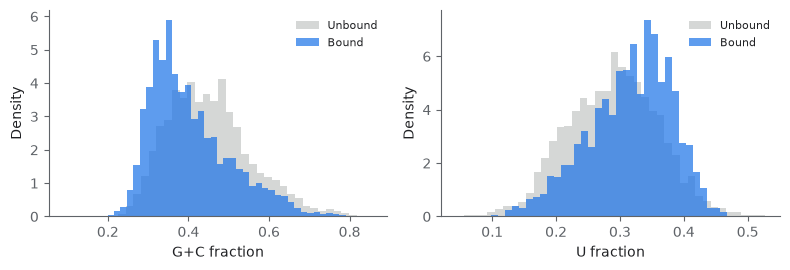

In [15]:
#@title Plot G+C and U content - run this cell { display-mode: "form" }
import matplotlib.pyplot as plt
C = gc_u(S_train)
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
for j, name in enumerate(("G+C fraction", "U fraction")):
    for lab, c, lbl in ((0, UNBOUND, "Unbound"), (1, BOUND, "Bound")):
        ax[j].hist(C[y_train == lab, j], bins=40, alpha=.7, color=c, label=lbl, density=True)
    ax[j].set_xlabel(name); ax[j].set_ylabel("Density"); ax[j].legend()
plt.tight_layout(); plt.show()

Recall from part 1 that each unbound sequence is a binding site moved to a random position in the
same gene. So this comparison sets binding sites against random positions in the same genes. Part of
a difference in composition may be real biology of where AGO2 binds (mostly in 3′UTRs, the stretch
of a messenger RNA after the protein-coding part, which is rich in A and U), and part may come from
how the unbound positions were drawn. Sequence length is also a weak shortcut (alone it gives an AUROC
of about 0.54); section 4 controls for it together with composition.

## 2. Word counts (TODO-2)

`kmer_counts(seqs, k=5)` turns each sequence into 1,024 numbers: how often each 5-letter word
occurs. A linear model on these counts sees which words appear, but not where or in what order.
Word counts can pick up short motifs too (a 7-letter site contains three 5-letter words); they lose
where the motif sits.

You first count the words of one short sequence yourself and compare your counts with
`kmer_counts` (TODO-2a). Then you fit the model on the counts of all sequences (TODO-2b).

**Tools:** `kmer_counts(seqs, k=5)` → an array with one row of 1,024 numbers per sequence, and
`probe_auc` as above.

In [16]:
#@title The 1,024 words and one short sequence - run this cell, nothing to change { display-mode: "form" }
import itertools
WORDS5 = ["".join(w) for w in itertools.product("ACGU", repeat=5)]   # column j of kmer_counts(seqs, 5) counts WORDS5[j]
s = min(S_train, key=len)
print(len(WORDS5), "words:", WORDS5[:3], "...", WORDS5[-2:])
print(f"the shortest training sequence, {len(s)} letters:\n{s}")

1024 words: ['AAAAA', 'AAAAC', 'AAAAG'] ... ['UUUUG', 'UUUUU']
the shortest training sequence, 190 letters:
GCGCGGCCGGAUUCACCACAACAUGGCAACUCUUUUUAUAAGGAAAAUGGUGAACCCUAUGCUAUAUCUCAGUCGUCACACAGUGAAGCCUCGAGCCCUCUCCACAUUUCUAUUUGGAUCCCUUCGAGGUGCAGCCCCCGUGGCUGUGGAACCCGGGGCAGAAGUGCGCUCACUUCUCUCACCCGGCCUC


In [17]:
# TODO-2a: write count_words(seq, k=5): how often each k-letter word occurs in seq, counting every
#          window of k neighbouring letters (the windows overlap), as a Counter: word -> count.
from collections import Counter


def count_words(seq, k=5):
    # === Your code here ===
    ...
    # === End of your code ===


counts = count_words(s)
total = sum(counts.values())
row = kmer_counts([s], 5)[0]            # the same sequence as 1,024 numbers
print(f"{total} windows, {len(counts)} different words")
print("kmer_counts gives each count as a fraction of all windows. The 6 most frequent words:")
print("word    your count   / windows   kmer_counts")
for w, n in counts.most_common(6):
    print(f"{w}   {n:10d}   {n / total:9.4f}   {row[WORDS5.index(w)]:11.4f}")

AttributeError: 'NoneType' object has no attribute 'values'

In [18]:
# TODO-2b: the test AUROC of a linear model on the 5-letter word counts of the sequences (the tools
#          above, trained and measured as in TODO-1c). Keep it as auc_k5.
# === Your code here ===
...
# === End of your code ===
table["5-letter word counts (1,024 numbers)"] = auc_k5
print(f"word counts: {auc_k5:.3f}")

NameError: name 'auc_k5' is not defined

In [19]:
#@title Test TODO-2 - run this cell, nothing to change { display-mode: "form" }
def test_words():
    rng = np.random.default_rng(0)
    seqs = [S_train[i] for i in rng.choice(len(S_train), 50, replace=False)]
    K = kmer_counts(seqs, 5)
    for n, seq in enumerate(seqs):
        c = count_words(seq)
        total = len(seq) - 5 + 1
        assert sum(c.values()) == total, \
            f"sequence {n} ({len(seq)} letters): {sum(c.values())} windows counted, want {total} (length - 5 + 1)"
        for j, w in enumerate(WORDS5):
            assert np.isclose(c.get(w, 0) / total, K[n, j], atol=1e-6), \
                (f"sequence {n}, word {w}: your count is {c.get(w, 0)}, kmer_counts gives "
                 f"{K[n, j]:.4f} of {total} windows = {K[n, j] * total:.0f}")
    assert 0.71 <= auc_k5 <= 0.77, \
        f"auc_k5 = {auc_k5:.3f}, want 0.71 to 0.77: train on the word counts of the training sequences, measure on the test sequences"
    print(f"TODO-2 passed: your word counts match kmer_counts on 50 sequences; auc_k5 = {auc_k5:.3f}")


test_words()

AttributeError: 'NoneType' object has no attribute 'values'

In [20]:
#@title Stuck? Run this only if the test failed: it defines our count_words and computes auc_k5 { display-mode: "form" }
def count_words(seq, k=5):
    return Counter(seq[i:i + k] for i in range(len(seq) - k + 1))


auc_k5, _ = probe_auc(kmer_counts(S_train, 5), y_train, kmer_counts(S_test, 5), y_test)
table["5-letter word counts (1,024 numbers)"] = auc_k5
test_words()

TODO-2 passed: your word counts match kmer_counts on 50 sequences; auc_k5 = 0.738


## 3. The shuffle test (TODO-3)

Take every **bound** test sequence and shuffle it with `dinuc_shuffle`. The result has the same
letters, the same letter pairs and the same G+C content, but any longer motif is broken up. Then
score these shuffled "bound" sequences against the real unbound ones.

The shuffled sequences keep their composition, so they still differ from the unbound ones in the
way TODO-1 measured. A model can therefore still separate them from composition alone, about as well
as your two-number model (`auc_gc`), and the AUROC has no reason to fall all the way to 0.5.

* A model that uses only composition (letters and letter pairs) scores about the same before and
  after the shuffle.
* A model that also uses letter order beyond neighbouring pairs, such as motifs, loses that part,
  and its AUROC drops towards the composition score `auc_gc`.
* The shuffle also moves a binding site out of letters 150–190. The CNN weights that region (part
  1), so for the CNN the drop mixes letter order and position.

First shuffle one sequence and check what the shuffle keeps (TODO-3a).

In [21]:
s = next(q for q, label in zip(S_test, y_test) if label == 1)     # one bound test sequence
s_shuf = dinuc_shuffle(s, np.random.default_rng(1))
print("original:", s[:60], "...")
print("shuffled:", s_shuf[:60], "...")

# TODO-3a: check what the shuffle kept. First write pair_counts(seq): how often each pair of
#          neighbouring letters occurs in seq, as a Counter.
def pair_counts(seq):
    # === Your code here ===
    ...
    # === End of your code ===


# TODO-3a, continued: `same_pairs` is True if s and s_shuf have the same pair counts, and
#          `same_sequence` is True if they are the same sequence.
# === Your code here ===
...
# === End of your code ===
pc, ps = pair_counts(s), pair_counts(s_shuf)
print("\nthe 16 letter-pair counts, original / shuffled:")
for a in "ACGU":
    print("   ".join(f"{a + b}: {pc[a + b]:3d} / {ps[a + b]:3d}" for b in "ACGU"))
print("\nsame 16 pair counts:", same_pairs, "| same sequence:", same_sequence)

original: UGUGGGAAGGGCUAUACCACUGCCUCAUACUUUCUUCUACAUCAGAGAAUUCAUAAAGGU ...
shuffled: UAAUCCUUCAGAUAAUUCCUAGACAACUGUACAUAAAGAUGGCUUUAGGAGUCAAUCAAU ...

the 16 letter-pair counts, original / shuffled:


TypeError: 'NoneType' object is not subscriptable

In [22]:
#@title Make the shuffled sequences - run this cell { display-mode: "form" }
rng = np.random.default_rng(0)
bound = [s for s, y in zip(S_test, y_test) if y == 1]
unbound = [s for s, y in zip(S_test, y_test) if y == 0]
shuffled = [dinuc_shuffle(s, rng) for s in bound]
print("original:", bound[0][:60])
print("shuffled:", shuffled[0][:60])
print("same G+C and U?", np.allclose(gc_u(bound), gc_u(shuffled)))
y_shuf = np.array([1] * len(shuffled) + [0] * len(unbound))

original: UGUGGGAAGGGCUAUACCACUGCCUCAUACUUUCUUCUACAUCAGAGAAUUCAUAAAGGU
shuffled: UGGUACCUAUUAAAAAAUGUAAAUAAAAGGUAACACUAUGCUCUAAAUCUUCUUUUAAUG
same G+C and U? True


### TODO-3b: Run the shuffle test on both models

Compute two AUROCs for the list `shuffled + unbound`, both against `y_shuf` (1 for the shuffled bound
sequences, 0 for the real unbound ones):

* **CNN** → `auc_shuf_cnn`, from the CNN's probability of "bound" for each sequence.
* **Language model** → `auc_shuf_fm`, from the probability of "bound" of the probe of part 2 on the
  embeddings of the sequences. The language model reads DNA, so U becomes T first (`to_dna`).

The models are the ones already trained on real sequences: `cnn`, and `probe` on top of the frozen
language model. Do **not** train anything on the shuffled sequences; the question is how the trained
models respond to them.

In [23]:
# TODO-3b: shuffle-test AUROC for the CNN and for Mistral-DNA + probe
# === Your code here ===
...
# === End of your code ===
print(f"CNN         : real {table['CNN (part 1)']:.3f}  ->  shuffled {auc_shuf_cnn:.3f}")
print(f"Mistral-DNA : real {probe_real:.3f}  ->  shuffled {auc_shuf_fm:.3f}")

NameError: name 'auc_shuf_cnn' is not defined

In [24]:
#@title Test TODO-3 - run this cell, nothing to change { display-mode: "form" }
def test_shuffle_test():
    got = pair_counts("ACGUA")
    assert got == Counter({"AC": 1, "CG": 1, "GU": 1, "UA": 1}), \
        f"pair_counts('ACGUA') = {dict(got)}, want AC, CG, GU and UA once each"
    assert same_pairs and not same_sequence, \
        f"same_pairs = {same_pairs} (want True), same_sequence = {same_sequence} (want False)"
    assert unbound == [q for q, label in zip(S_test, y_test) if label == 0], \
        "unbound is no longer the list of real unbound test sequences: the test shuffles only the bound ones"
    assert len(shuffled) == len(bound), f"shuffled has {len(shuffled)} sequences, want {len(bound)}, one per bound sequence"
    ref = roc_auc_score(y_shuf, score_sequences(cnn, shuffled + unbound))
    assert abs(auc_shuf_cnn - ref) < 1e-6, \
        (f"auc_shuf_cnn = {auc_shuf_cnn:.3f}, but the CNN scores {ref:.3f} on shuffled + unbound against y_shuf. "
         "Score the list shuffled + unbound in this order, and keep the unbound sequences unshuffled")
    ref_fm = roc_auc_score(y_shuf, probe.predict_proba(embed(tok, fm, [to_dna(q) for q in shuffled + unbound]))[:, 1])
    assert abs(auc_shuf_fm - ref_fm) < 2e-3, \
        (f"auc_shuf_fm = {auc_shuf_fm:.3f}, but the probe of part 2 scores {ref_fm:.3f} on shuffled + unbound "
         "against y_shuf. Use the embeddings of these sequences as DNA and the probe already trained on real sequences")
    print(f"TODO-3 passed: the shuffle keeps the letter pairs; CNN {auc_shuf_cnn:.3f}, "
          f"Mistral-DNA + probe {auc_shuf_fm:.3f}, with the unbound sequences unshuffled")


test_shuffle_test()

TypeError: 'NoneType' object is not iterable

In [25]:
#@title Stuck? Run this only if the test failed: it runs the shuffle test for you { display-mode: "form" }
def pair_counts(seq):
    return Counter(seq[i:i + 2] for i in range(len(seq) - 1))


same_pairs, same_sequence = pair_counts(s) == pair_counts(s_shuf), s == s_shuf
auc_shuf_cnn = roc_auc_score(y_shuf, score_sequences(cnn, shuffled + unbound))
auc_shuf_fm = roc_auc_score(y_shuf, probe.predict_proba(embed(tok, fm, [to_dna(s) for s in shuffled + unbound]))[:, 1])
print(f"CNN         : real {table['CNN (part 1)']:.3f}  ->  shuffled {auc_shuf_cnn:.3f}")
print(f"Mistral-DNA : real {probe_real:.3f}  ->  shuffled {auc_shuf_fm:.3f}")
test_shuffle_test()

CNN         : real 0.867  ->  shuffled 0.667
Mistral-DNA : real 0.782  ->  shuffled 0.765


TODO-3 passed: the shuffle keeps the letter pairs; CNN 0.667, Mistral-DNA + probe 0.765, with the unbound sequences unshuffled


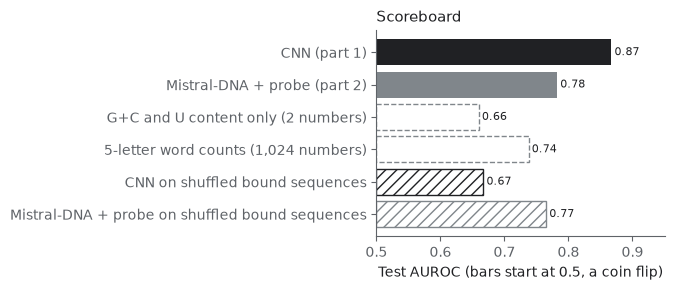

In [26]:
#@title The scoreboard - run this cell { display-mode: "form" }
import json
results = dict(table)
results["CNN on shuffled bound sequences"] = auc_shuf_cnn
results["Mistral-DNA + probe on shuffled bound sequences"] = auc_shuf_fm
# CNN = ink, frozen language model = mid grey, shortcut baselines = dashed grey outline, shuffled = hatched
styles = {"CNN (part 1)": dict(color=CNN_C),
          "Mistral-DNA + probe (part 2)": dict(color=FROZEN_C),
          "G+C and U content only (2 numbers)": dict(color="white", edgecolor=BASELINE_C, linestyle="--"),
          "5-letter word counts (1,024 numbers)": dict(color="white", edgecolor=BASELINE_C, linestyle="--"),
          "CNN on shuffled bound sequences": dict(color="white", edgecolor=CNN_C, hatch="///"),
          "Mistral-DNA + probe on shuffled bound sequences": dict(color="white", edgecolor=FROZEN_C, hatch="///")}
names = [k for k in styles if k in results]
fig, ax = plt.subplots(figsize=(7, 3))
for i, k in enumerate(names):
    ax.barh(i, results[k] - 0.5, left=0.5, linewidth=1, **styles[k])
    ax.text(results[k] + 0.005, i, f"{results[k]:.2f}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(names)), names)
ax.set_xlim(0.5, 0.95); ax.invert_yaxis()
ax.set_xlabel("Test AUROC (bars start at 0.5, a coin flip)"); ax.set_title("Scoreboard")
plt.tight_layout(); plt.show()
_ = (DATA_DIR / "my_part3_shuffle_results.json").write_text(json.dumps(results, indent=1))

### Discuss

1. How much of each model's score can two numbers reproduce?
2. Which model was least affected by the shuffle? Compare its shuffled score with the composition
   score `auc_gc`. What does that suggest it relies on?
3. Two numbers (G+C and U) already separate the classes. The unbound sequences are random positions in
   the same genes as the binding sites. Which part of the composition difference could be biology
   (AGO2 binds mostly in A/U-rich 3′UTRs), and which part could come from how the unbound positions
   were drawn?

From section 4 on, we change the data and leave the models as they are.

# Fix the data, then test again (sections 4 to 8)

In sections 1 to 3, two numbers (the G+C and U fractions of a sequence) already separated bound from
unbound RNA (AUROC ≈ 0.66). Each unbound sequence is a binding site moved to a random position in
the same gene (part 1), so this compares binding sites with random positions in the same genes. Part
of the difference may be real biology of where AGO2 binds (mostly in A/U-rich 3′UTRs), and part may
come from how the unbound positions were drawn. Either way, a model trained on these data can score
well by reading single-letter composition, and the score alone would not show it.

A **control** removes that signal. We select bound and unbound sequences so that both classes have
the same G+C fraction, U fraction and length, bin by bin. On the selected data, single-letter
composition carries no information about the label. Letter-pair and 5-letter-word composition still
differ between the classes, so a score above 0.5 can still come from them.

## 4. A composition-matched benchmark

We sort every training sequence into a bin by its G+C fraction, U fraction and length. In each bin
we keep the **same number of bound and unbound sequences** (the smaller of the two counts) and drop
the rest. This selects a subset of **both** classes: about 30% of the bound sequences have no
unbound match in their bin and are dropped. Afterwards the two classes have the same single-letter
composition and length, bin by bin.

For comparison we also draw an equally large random subset of the same file, with the bound and
unbound sequences as they were. Each benchmark keeps 3,000 sequences aside for testing: the
**original-negatives test set** and the **matched test set**. Both come from the training file, so
they differ from the 1,000-sequence held-out test set used in parts 1 and 2 and in sections 1 to 3. The
models also train differently here (the CNN for 6 epochs on about 65,000 sequences), so the
"original" numbers below differ slightly from those of sections 1 to 3.

matching kept 33,882 of 48,095 bound sequences
original: train 64,764 | test 3,000 | bound 52%
matched : train 64,764 | test 3,000 | bound 50%


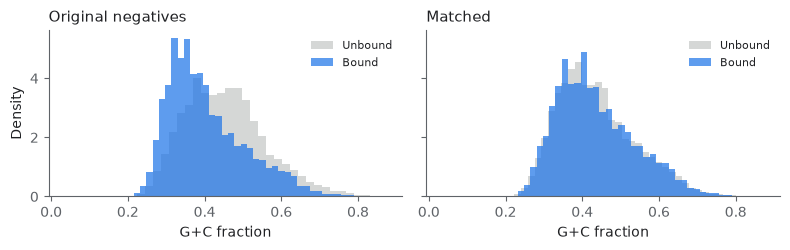

In [27]:
#@title Build the two benchmarks - run this cell, nothing to change { display-mode: "form" }
import matplotlib.pyplot as plt

all_seqs, all_y = read_split("train")


def matched_indices(seqs, y, seed=0):
    rng = np.random.default_rng(seed)
    C = gc_u(seqs)
    L = np.array([len(s) for s in seqs])
    key = (np.clip((C[:, 0] * 12 / 0.8).astype(int), 0, 11) * 100
           + np.clip((C[:, 1] * 12 / 0.6).astype(int), 0, 11) * 10
           + np.clip((L - 130) // 60, 0, 4))
    keep = []
    for k in np.unique(key[y == 1]):
        p = np.nonzero((key == k) & (y == 1))[0]
        n = np.nonzero((key == k) & (y == 0))[0]
        m = min(len(p), len(n))
        keep += list(rng.choice(p, m, replace=False)) + list(rng.choice(n, m, replace=False))
    keep = np.array(keep)
    rng.shuffle(keep)
    return keep


N_TEST = 3000
m_idx = matched_indices(all_seqs, all_y)
o_idx = np.random.default_rng(1).permutation(len(all_seqs))[:len(m_idx)]   # same size, original negatives
print(f"matching kept {int(all_y[m_idx].sum()):,} of {int(all_y.sum()):,} bound sequences")
BENCH = {}
for name, idx in (("original", o_idx), ("matched", m_idx)):
    te, tr = idx[:N_TEST], idx[N_TEST:]
    BENCH[name] = ([all_seqs[i] for i in tr], all_y[tr], [all_seqs[i] for i in te], all_y[te])
    print(f"{name:8s}: train {len(tr):,} | test {len(te):,} | bound {all_y[tr].mean():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(8, 2.6), sharex=True, sharey=True)
for a, name in zip(ax, BENCH):
    S, y = BENCH[name][0], BENCH[name][1]
    g = gc_u(S)[:, 0]
    for lab, c, lbl in ((0, UNBOUND, "Unbound"), (1, BOUND, "Bound")):
        a.hist(g[y == lab], bins=40, alpha=.7, color=c, density=True, label=lbl)
    a.set_title("Original negatives" if name == "original" else "Matched"); a.set_xlabel("G+C fraction"); a.legend()
ax[0].set_ylabel("Density")
plt.tight_layout(); plt.show()

Two benchmarks of **equal size**, drawn from the same file: `original` keeps the sequences as they
were, `matched` uses the composition-matched subset. Every model below is trained and tested on both,
so the two columns of results differ only in how the sequences were selected.

### One function, two benchmarks

`shortcut_scores(train_seqs, train_y, test_seqs, test_y)` repeats TODO-1, TODO-2 and the frozen
probe of part 2 on one benchmark. It takes the first 12,000 training sequences as `tr`, `ytr` and
computes three test AUROCs:

| variable | features for `probe_auc` |
|---|---|
| `auc_gc` | `gc_u(tr)` and `gc_u(test_seqs)` |
| `auc_k5` | `kmer_counts(tr, 5)` and `kmer_counts(test_seqs, 5)` |
| `auc_fm` | `embed(tok, fm, [to_dna(s) for s in tr])`, same for `test_seqs` |

The function is called twice, once per benchmark, so it uses only its arguments and `tok`, `fm`.

In [28]:
#@title Three simple models on both benchmarks - run this cell, nothing to change { display-mode: "form" }
def shortcut_scores(train_seqs, train_y, test_seqs, test_y, n=12000):
    tr, ytr = train_seqs[:n], train_y[:n]
    auc_gc, _ = probe_auc(gc_u(tr), ytr, gc_u(test_seqs), test_y)
    auc_k5, _ = probe_auc(kmer_counts(tr, 5), ytr, kmer_counts(test_seqs, 5), test_y)
    auc_fm, _ = probe_auc(embed(tok, fm, [to_dna(s) for s in tr]), ytr,
                          embed(tok, fm, [to_dna(s) for s in test_seqs]), test_y)
    return {"G+C and U content only (2 numbers)": auc_gc,
            "5-letter word counts (1,024 numbers)": auc_k5,
            "Mistral-DNA + probe (frozen)": auc_fm}


scores = {name: shortcut_scores(*BENCH[name]) for name in BENCH}
for k in scores["original"]:
    print(f"{k:38s} original {scores['original'][k]:.3f} | matched {scores['matched'][k]:.3f}")

G+C and U content only (2 numbers)     original 0.637 | matched 0.510
5-letter word counts (1,024 numbers)   original 0.762 | matched 0.725
Mistral-DNA + probe (frozen)           original 0.806 | matched 0.770


## 5. Retrain the CNN on both benchmarks

Same architecture as part 1, 6 epochs on each training set of about 65,000 sequences.
The three models above used 12,000 of them.

In [29]:
#@title Retrain the CNN twice - run this cell, nothing to change { display-mode: "form" }
from torch.utils.data import DataLoader, TensorDataset
for name in BENCH:
    S_tr, y_tr, S_te, y_te = BENCH[name]
    t0 = time.time()
    torch.manual_seed(SEED)
    cnn_b = GlobalCNN().to(DEVICE)
    cnn_opt = optim.Adam(cnn_b.parameters(), lr=1e-3, weight_decay=1e-4)
    cnn_crit = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(encode_batch(S_tr), torch.tensor(y_tr, dtype=torch.float32)),
                        batch_size=256, shuffle=True, drop_last=True)
    for ep in range(6):
        cnn_b.train()
        for X, y in loader:
            cnn_opt.zero_grad()
            cnn_crit(cnn_b(X.to(DEVICE)), y.to(DEVICE)).backward()
            cnn_opt.step()
    scores[name]["CNN (part 1 architecture)"] = roc_auc_score(y_te, score_sequences(cnn_b, S_te))
    print(f"CNN, {name:8s}: {scores[name]['CNN (part 1 architecture)']:.3f}  ({time.time() - t0:.0f}s)")

CNN, original: 0.843  (8s)


CNN, matched : 0.838  (8s)


## 6. Fine-tuning with LoRA (TODO-4)

So far the language model was **frozen**: we only trained a linear probe on top. **Fine-tuning**
also updates the model's own weights for the AGO2 task. Large models are usually adapted with **LoRA**
(low-rank adaptation), so we practise it here on Mistral-DNA. LoRA keeps every adapted weight matrix
$W$ fixed and learns a small correction added to it: $W x$ becomes $(W + BA)\,x$. $B$ and $A$ are thin
matrices with a small inner size $r$ (the *rank*); only they, and a new output layer, are trained.

We train on the **matched** benchmark, 2 epochs over 20,000 labelled sequences (the frozen probe used
12,000), and test on the matched test set. The training step is the one of part 1, and it is given.
Before training, you work out how small LoRA's correction is (TODO-4a) and predict the result (TODO-4b).

In [30]:
#@title Set up LoRA - run this cell, nothing to change { display-mode: "form" }
!pip -q install peft==0.21.2   # pinned version
# remove a package that this peft version cannot load (not used here)
!pip -q uninstall -y torchao
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForSequenceClassification


def make_lora():
    """A fresh Mistral-DNA (16M) with LoRA add-ons, its optimizer, and a gradient scaler."""
    torch.manual_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(FM_REPO, num_labels=1, trust_remote_code=True)
    model = model.float()
    model.config.pad_token_id = tok.pad_token_id
    model = get_peft_model(model, LoraConfig(r=16, lora_alpha=16, lora_dropout=0.05, bias="none", task_type="SEQ_CLS",
                                             target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])).to(DEVICE)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=5e-4)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
    return model, optimizer, scaler


clf, opt, scaler = make_lora()
crit = nn.BCEWithLogitsLoss()
LORA_EPOCHS, LORA_N = 2, 20000
M_tr, my_tr, M_te, my_te = BENCH["matched"]
D_tr, ytr, D_te = [to_dna(s) for s in M_tr[:LORA_N]], my_tr[:LORA_N], [to_dna(s) for s in M_te]


def batch_logits(seqs):
    enc = tok(seqs, return_tensors="pt", padding=True, truncation=True, max_length=256)
    with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
        return clf(input_ids=enc["input_ids"].to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE)).logits.float().squeeze(-1)


@torch.no_grad()
def lora_auc():
    clf.eval()
    s = np.concatenate([batch_logits(D_te[i:i + 256]).cpu().numpy() for i in range(0, len(D_te), 256)])
    clf.train()
    return roc_auc_score(my_te, s)


def lora_step(seqs, y):
    """One training step of clf on one batch (the training step of part 1). Returns the loss."""
    loss = crit(batch_logits(seqs), y)
    opt.zero_grad()
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    return loss


R = 16                                   # the rank r of B and A
W = {n.split(".")[-3]: tuple(p.shape) for n, p in clf.named_parameters()
     if ".layers.0." in n and n.endswith("base_layer.weight")}
n_layers = len({n.split(".layers.")[1].split(".")[0] for n, _ in clf.named_parameters() if ".layers." in n})
print(f"LoRA adapts {len(W)} matrices W in each of the {n_layers} layers; rank r = {R}")
for name, shape in W.items():
    print(f"  {name}: W has {shape[0]} rows and {shape[1]} columns")

Loading weights:   0%|          | 0/74 [00:00<?, ?it/s]

LoRA adapts 4 matrices W in each of the 8 layers; rank r = 16
  q_proj: W has 256 rows and 256 columns
  k_proj: W has 256 rows and 256 columns
  v_proj: W has 256 rows and 256 columns
  o_proj: W has 256 rows and 256 columns


In [31]:
# TODO-4a: LoRA adds B·A to each of these matrices W. B has as many rows as W and r columns; A has r
#          rows and as many columns as W. Compute n_lora, the number of trainable numbers in all B and A
#          matrices of the model, and n_W, the number of numbers in the same matrices W, which stay fixed.
# === Your code here ===
...
# === End of your code ===
print(f"LoRA trains {n_lora:,} numbers to adapt {n_W:,} fixed ones ({n_lora / n_W:.1%})")

NameError: name 'n_lora' is not defined

In [32]:
#@title Test TODO-4a - run this cell, nothing to change { display-mode: "form" }
def test_lora_count():
    real = sum(p.numel() for n, p in clf.named_parameters() if "lora_" in n)
    real_W = sum(p.numel() for n, p in clf.named_parameters() if n.endswith("base_layer.weight"))
    assert n_W == real_W, f"n_W = {n_W:,}, want {real_W:,}: the numbers in all adapted matrices W (rows x columns), in every layer"
    assert n_lora == real, \
        (f"n_lora = {n_lora:,}, the model has {real:,}: for a W with m rows and n columns, B has m x r numbers "
         f"and A has r x n, in every adapted matrix of every layer")
    n_all = sum(p.numel() for p in clf.parameters())
    print(f"TODO-4a passed: {real:,} LoRA numbers; with the new output layer the model trains "
          f"{sum(p.numel() for p in clf.parameters() if p.requires_grad):,} of its {n_all:,} parameters")


test_lora_count()

NameError: name 'n_W' is not defined

In [33]:
#@title Stuck? Run this only if the test failed: it computes both counts for you { display-mode: "form" }
n_lora = n_layers * sum(R * (rows + cols) for rows, cols in W.values())
n_W = n_layers * sum(rows * cols for rows, cols in W.values())
test_lora_count()

TODO-4a passed: 262,144 LoRA numbers; with the new output layer the model trains 262,400 of its 16,012,032 parameters


In [34]:
#@title The models so far on the matched test set - run this cell { display-mode: "form" }
for k in ("Mistral-DNA + probe (frozen)", "CNN (part 1 architecture)"):
    print(f"{k:32s} matched test AUROC {scores['matched'][k]:.3f}")

Mistral-DNA + probe (frozen)     matched test AUROC 0.770
CNN (part 1 architecture)        matched test AUROC 0.838


In [35]:
# TODO-4b: before training, write your prediction: will the fine-tuned Mistral-DNA score higher or lower
#          than the frozen probe and than the CNN on the matched test set, and why? (Free text; the
#          training cell prints it next to the result.)
MY_PREDICTION = ""

In [36]:
#@title Train with LoRA - run this cell, nothing to change { display-mode: "form" }
clf, opt, scaler = make_lora()   # a fresh model every time this cell runs
t0 = time.time()
clf.train()
for epoch in range(LORA_EPOCHS):
    order = np.random.default_rng(epoch).permutation(len(D_tr))
    for step, i in enumerate(range(0, len(order), 32)):
        b = order[i:i + 32]
        y = torch.tensor(ytr[b], dtype=torch.float32, device=DEVICE)
        loss = lora_step([D_tr[j] for j in b], y)
        if step % 200 == 0:
            print(f"epoch {epoch + 1} step {step:4d} | loss {loss.item():.3f} | {time.time() - t0:.0f}s")
    print(f"--> after epoch {epoch + 1}: matched test AUROC {lora_auc():.3f}")
scores["matched"]["Mistral-DNA, LoRA fine-tuned"] = lora_auc()
print()
print(f"LoRA fine-tuned: {scores['matched']['Mistral-DNA, LoRA fine-tuned']:.3f} | frozen + probe: "
      f"{scores['matched']['Mistral-DNA + probe (frozen)']:.3f} | CNN: {scores['matched']['CNN (part 1 architecture)']:.3f}")
print("your prediction:", MY_PREDICTION or "(none written)")

Loading weights:   0%|          | 0/74 [00:00<?, ?it/s]

epoch 1 step    0 | loss 0.680 | 0s


epoch 1 step  200 | loss 0.542 | 14s


epoch 1 step  400 | loss 0.589 | 28s


epoch 1 step  600 | loss 0.418 | 42s


...

epoch 2 step  200 | loss 0.409 | 60s


epoch 2 step  400 | loss 0.421 | 75s


epoch 2 step  600 | loss 0.625 | 90s


--> after epoch 2: matched test AUROC 0.809



LoRA fine-tuned: 0.809 | frozen + probe: 0.770 | CNN: 0.838
your prediction: (none written)


## 7. Before and after the control

In [37]:
#@title The before/after table - run this cell { display-mode: "form" }
import json
print(f"{'model':40s} {'original':>9s} {'matched':>9s}   lost to the control")
for k in scores["original"]:
    if k not in scores["matched"]:
        continue
    o, m = scores["original"][k], scores["matched"][k]
    print(f"{k:40s} {o:9.3f} {m:9.3f}   {'█' * int(round(max(o - m, 0) * 200))} {o - m:+.3f}")
k = "Mistral-DNA, LoRA fine-tuned"
if k in scores["matched"]:
    print(f"{k:40s} {'':9s} {scores['matched'][k]:9.3f}")
print()
print("(each █ = 0.005 AUROC lost once single-letter composition is matched)")
print("(labelled training sequences: CNN about 65,000; LoRA 20,000; the other three 12,000)")
_ = (DATA_DIR / "my_part3_matched_results.json").write_text(json.dumps(scores, indent=1))

model                                     original   matched   lost to the control
G+C and U content only (2 numbers)           0.637     0.510   █████████████████████████ +0.127
5-letter word counts (1,024 numbers)         0.762     0.725   ███████ +0.037
Mistral-DNA + probe (frozen)                 0.806     0.770   ███████ +0.036
CNN (part 1 architecture)                    0.843     0.838   █ +0.005
Mistral-DNA, LoRA fine-tuned                           0.809

(each █ = 0.005 AUROC lost once single-letter composition is matched)
(labelled training sequences: CNN about 65,000; LoRA 20,000; the other three 12,000)


## 8. Pretraining and the number of labels (optional)

The table above compares models trained on different numbers of labels: about 65,000 for the CNN,
20,000 for LoRA and 12,000 for the others. A lab studying a new question often has fewer labels.

The next cell compares both approaches trained on 100 to 12,000 labelled sequences (matched
benchmark, matched test set). The light grey dashed line is the same language model with **random
weights**. A random network still produces features, so this line shows how much of the probe's
score depends on pretraining.

**This cell is optional and precomputed.** By default it plots our offline results (3 random draws
of the labels per size: points are means, bars are standard deviations) and prints our offline
NT-500M head-to-head. Set `RUN_LIVE = True` to rerun one draw at 4 sizes yourself.

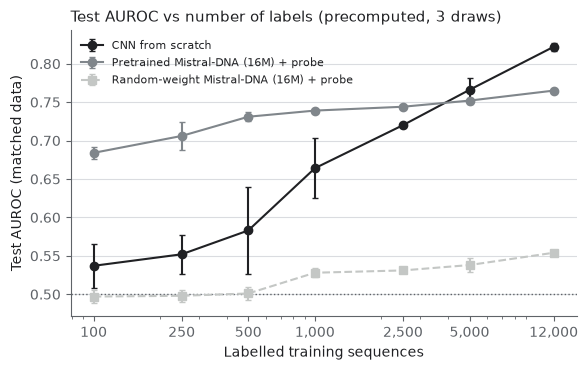

Offline head-to-head with NT-500M on the matched test set:
   500 labels | CNN from scratch 0.655 | NT-500M + probe (frozen) 0.733 | NT-500M, LoRA fine-tuned 0.750
20,000 labels | CNN from scratch 0.835 | NT-500M + probe (frozen) 0.783 | NT-500M, LoRA fine-tuned 0.869


In [38]:
#@title Learn from fewer labels (optional; precomputed by default) { display-mode: "form" }
RUN_LIVE = False   # True = rerun the label curve yourself (one draw per size)

# Our offline runs on this matched benchmark and test set: mean and standard deviation over 3 draws.
PRECOMPUTED = {
    "NS": [100, 250, 500, 1000, 2500, 5000, 12000],
    "CNN from scratch": {"mean": [0.537, 0.552, 0.583, 0.664, 0.720, 0.766, 0.822],
                         "sd":   [0.029, 0.025, 0.057, 0.039, 0.003, 0.016, 0.005]},
    "Pretrained Mistral-DNA (16M) + probe": {"mean": [0.684, 0.706, 0.731, 0.739, 0.744, 0.752, 0.765],
                                             "sd":   [0.008, 0.018, 0.006, 0.001, 0.001, 0.004, 0.001]},
    "Random-weight Mistral-DNA (16M) + probe": {"mean": [0.497, 0.498, 0.501, 0.528, 0.531, 0.538, 0.554],
                                                "sd":   [0.009, 0.008, 0.008, 0.006, 0.003, 0.009, 0.004]},
}
# Our offline head-to-head with NT-500M on the same matched test set (CNN and LoRA: mean of 3 seeds;
# frozen probe: one run).
HEAD_TO_HEAD = {500: {"CNN from scratch": 0.655, "NT-500M + probe (frozen)": 0.733, "NT-500M, LoRA fine-tuned": 0.750},
                20000: {"CNN from scratch": 0.835, "NT-500M + probe (frozen)": 0.783, "NT-500M, LoRA fine-tuned": 0.869}}

if RUN_LIVE:
    from transformers import AutoConfig, AutoModel
    M_tr, my_tr, M_te, my_te = BENCH["matched"]
    POOL = 12000
    t0 = time.time()
    D_pool, D_test = [to_dna(s) for s in M_tr[:POOL]], [to_dna(s) for s in M_te]
    E_pool, E_mtest = embed(tok, fm, D_pool), embed(tok, fm, D_test)   # E_mtest: not the rejoin cell's E_test
    torch.manual_seed(SEED)
    fm_rand = AutoModel.from_config(AutoConfig.from_pretrained(FM_REPO)).to(DEVICE).eval()
    R_pool, R_test = embed(tok, fm_rand, D_pool), embed(tok, fm_rand, D_test)
    del fm_rand
    X_pool, y_pool = encode_batch(M_tr[:POOL]), my_tr[:POOL]

    def cnn_from_scratch(sel, seed=0):
        """Part 1's CNN trained on `sel` only; stops early using 10% of `sel` (never the test set)."""
        sel = np.random.default_rng(seed).permutation(sel)
        nv = max(len(sel) // 10, 10)
        va, tr = sel[:nv], sel[nv:]
        torch.manual_seed(seed)
        model = GlobalCNN().to(DEVICE)
        opt_c = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
        crit_c = nn.BCEWithLogitsLoss()
        bs = min(256, max(16, len(tr) // 8))
        epochs = int(np.clip(1500 / max(len(tr) // bs, 1), 6, 200))
        best, best_state, bad = -1, None, 0
        for ep in range(epochs):
            model.train()
            perm = torch.randperm(len(tr))
            for i in range(0, len(tr), bs):
                b = tr[perm[i:i + bs].numpy()]
                opt_c.zero_grad()
                crit_c(model(X_pool[b].to(DEVICE)), torch.tensor(y_pool[b], dtype=torch.float32, device=DEVICE)).backward()
                opt_c.step()
            v = roc_auc_score(y_pool[va], score_sequences(model, [M_tr[i] for i in va]))
            if v > best:
                best, bad, best_state = v, 0, {k: t.clone() for k, t in model.state_dict().items()}
            else:
                bad += 1
                if bad >= 8:
                    break
        model.load_state_dict(best_state)
        return roc_auc_score(my_te, score_sequences(model, M_te))

    NS = [100, 500, 2500, 12000]
    curve = {k: {"mean": [], "sd": None} for k in list(PRECOMPUTED)[1:]}
    for n in NS:
        sel = np.random.default_rng(n).choice(POOL, n, replace=False)
        C = 0.01 if n < 2500 else 0.1          # stronger regularisation (smaller C) for small training sets
        curve["Pretrained Mistral-DNA (16M) + probe"]["mean"].append(probe_auc(E_pool[sel], y_pool[sel], E_mtest, my_te, C)[0])
        curve["Random-weight Mistral-DNA (16M) + probe"]["mean"].append(probe_auc(R_pool[sel], y_pool[sel], R_test, my_te, C)[0])
        curve["CNN from scratch"]["mean"].append(cnn_from_scratch(sel))
        print(f"{n:6,} labels | " + " | ".join(f"{k} {v['mean'][-1]:.3f}" for k, v in curve.items()))
    print(f"({time.time() - t0:.0f}s)")
else:
    NS = PRECOMPUTED["NS"]
    curve = {k: v for k, v in PRECOMPUTED.items() if k != "NS"}

curve_styles = {"CNN from scratch": dict(c=CNN_C, ls="-", marker="o"),
          "Pretrained Mistral-DNA (16M) + probe": dict(c=FROZEN_C, ls="-", marker="o"),
          "Random-weight Mistral-DNA (16M) + probe": dict(c=LIGHTGREY, ls="--", marker="s")}
plt.figure(figsize=(6, 3.8))
for k, v in curve.items():
    plt.errorbar(NS, v["mean"], yerr=v["sd"], capsize=2, label=k, **curve_styles[k])
plt.axhline(0.5, ls=":", c=MUTED, lw=1)
plt.xscale("log"); plt.xticks(NS, [f"{n:,}" for n in NS])
plt.xlabel("Labelled training sequences"); plt.ylabel("Test AUROC (matched data)")
plt.title("Test AUROC vs number of labels" + ("" if RUN_LIVE else " (precomputed, 3 draws)"))
plt.legend(); plt.grid(axis="y"); plt.tight_layout(); plt.show()

print("Offline head-to-head with NT-500M on the matched test set:")
for n, row in HEAD_TO_HEAD.items():
    print(f"{n:6,} labels | " + " | ".join(f"{k} {v:.3f}" for k, v in row.items()))

### What to take away

* **Frozen probe.** It still scores about 0.77 after matching, and in section 3 it barely changed under
  the shuffle. So it relies mostly on short-word composition (letter pairs, 5-letter words), which
  the matching leaves in place, and little on single letters.
* **CNN.** It lost almost nothing to the matched control (0.84 → 0.84), so it uses more than
  single-letter composition.
* **Fine-tuning.** Your fine-tuned Mistral-DNA (≈ 0.81) improved on the frozen probe (≈ 0.77) but
  stayed below the CNN (≈ 0.84). In our offline runs a 30× larger model, NT-500M with LoRA, reached
  0.87 against the CNN's 0.84 with 20,000 labels, and 0.75 against 0.66 with 500 labels (3 seeds each
  for the CNN and LoRA). Those fine-tuned models have not yet been put through the shuffle test.
* **Labels.** With few labels the frozen probe does better than the CNN, and with 100 labels the CNN
  is close to a coin flip. The random-weight line stays close to 0.5 (at most about 0.55), so the
  probe's advantage comes from pretraining on the genome.